# Figure 2. Taxonomic batch structure and diversity

Taxonomic alpha-diversity, distance matrices, PCoA ordination, and PERMANOVA for study-level batch effect versus clinical group.

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import mannwhitneyu
from skbio import DistanceMatrix
from skbio.diversity import beta_diversity
from skbio.diversity.alpha import observed_features, shannon, simpson
from skbio.stats.ordination import pcoa

from config import (
    CLR_PSEUDO,
    DEFAULT_METADATA_PATH,
    DEFAULT_TAX_PATH,
    DIST_DIR,
    FIGURE_OUTPUT_DIR,
    META_COLS,
)
from common import (
    assign_group,
    benjamini_hochberg,
    confidence_ellipse,
    numeric_feature_frame,
    permanova_r2,
    pval_to_stars,
    read_csv_with_run,
)

FIG_DIR = FIGURE_OUTPUT_DIR / "Fig_2_taxonomic_batch_diversity"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DIST_DIR.mkdir(parents=True, exist_ok=True)

GROUP_ORDER = ["Healthy", "Caries (K02)", "Periodontitis (K05)", "K02+K05"]
PALETTE = {
    "Healthy": "#7DAF86",
    "Caries (K02)": "#C9A86C",
    "Periodontitis (K05)": "#7B80C0",
    "K02+K05": "#8DAAB8",
}

## Load taxonomic profiles and metadata

In [2]:
tax_raw = read_csv_with_run(DEFAULT_TAX_PATH).set_index("run")
metadata = read_csv_with_run(DEFAULT_METADATA_PATH).set_index("run")

common_runs = metadata.index.intersection(tax_raw.index)
if len(common_runs) == 0:
    raise ValueError("No common runs between metadata and taxonomic table")

metadata = metadata.loc[common_runs].copy()
tax_raw = tax_raw.loc[common_runs].copy()

feature_cols = [col for col in tax_raw.columns if col not in META_COLS]
tax_data = numeric_feature_frame(tax_raw, feature_cols)

metadata["group"] = metadata.apply(assign_group, axis=1)
metadata = metadata[metadata["group"] != "Unknown"].copy()
tax_data = tax_data.loc[metadata.index]

print(f"Samples: {len(metadata)}")
print(f"Taxonomic features: {tax_data.shape[1]}")
print(f"Bioprojects: {metadata['bioproject'].nunique()}")
print(metadata["group"].value_counts().reindex(GROUP_ORDER).fillna(0).astype(int))

Samples: 514
Taxonomic features: 719
Bioprojects: 14
group
Healthy                204
Caries (K02)           149
Periodontitis (K05)    130
K02+K05                 31
Name: count, dtype: int64


## Alpha-diversity

In [3]:
metadata["observed"] = tax_data.apply(lambda row: observed_features(row.values), axis=1)
metadata["shannon"] = tax_data.apply(lambda row: shannon(row.values), axis=1)
metadata["simpson"] = tax_data.apply(lambda row: simpson(row.values), axis=1)

bp_group_counts = metadata.groupby("bioproject")["group"].nunique()
valid_bioprojects = bp_group_counts[bp_group_counts >= 2].index
metadata_alpha = metadata[metadata["bioproject"].isin(valid_bioprojects)].copy()

print(f"Bioprojects used for alpha panels: {len(valid_bioprojects)}")

Bioprojects used for alpha panels: 10


In [4]:
def alpha_test_table(metadata_alpha: pd.DataFrame) -> pd.DataFrame:
    rows = []
    metrics = ["observed", "shannon", "simpson"]
    bp_order = metadata_alpha["bioproject"].unique().tolist()

    for metric in metrics:
        for bp in bp_order:
            sub = metadata_alpha[metadata_alpha["bioproject"] == bp]
            present_groups = [
                group for group in GROUP_ORDER
                if len(sub.loc[sub["group"] == group, metric].dropna()) >= 3
            ]
            if len(present_groups) < 2:
                continue

            for group1, group2 in combinations(present_groups, 2):
                values1 = sub.loc[sub["group"] == group1, metric].dropna()
                values2 = sub.loc[sub["group"] == group2, metric].dropna()
                if len(values1) < 3 or len(values2) < 3:
                    continue

                _, p_value = mannwhitneyu(values1, values2, alternative="two-sided")
                rows.append({
                    "metric": metric,
                    "bioproject": bp,
                    "group1": group1,
                    "group2": group2,
                    "p_value": p_value,
                })

    test_df = pd.DataFrame(rows)
    if not test_df.empty:
        test_df["q_value"] = benjamini_hochberg(test_df["p_value"].values)
    return test_df


alpha_tests = alpha_test_table(metadata_alpha)
alpha_tests.sort_values("q_value").head(20) if not alpha_tests.empty else alpha_tests

,metric,bioproject,group1,group2,p_value,q_value
15,observed,PRJNA929548,Healthy,Caries (K02),0.000001,0.000057
32,shannon,PRJNA929548,Healthy,Caries (K02),0.000033,0.000841
49,simpson,PRJNA929548,Healthy,Caries (K02),0.000992,0.016865
29,shannon,PRJNA717815,Healthy,Periodontitis (K05),0.001560,0.019894
46,simpson,PRJNA717815,Healthy,Periodontitis (K05),0.004309,0.043951
1,observed,PRJNA1057503,Healthy,Periodontitis (K05),0.006273,0.053320
45,simpson,PRJNA932553,Healthy,Periodontitis (K05),0.012172,0.088678
28,shannon,PRJNA932553,Healthy,Periodontitis (K05),0.018513,0.118023
12,observed,PRJNA717815,Healthy,Periodontitis (K05),0.037243,0.172670
18,shannon,PRJNA1057503,Healthy,Periodontitis (K05),0.034684,0.172670


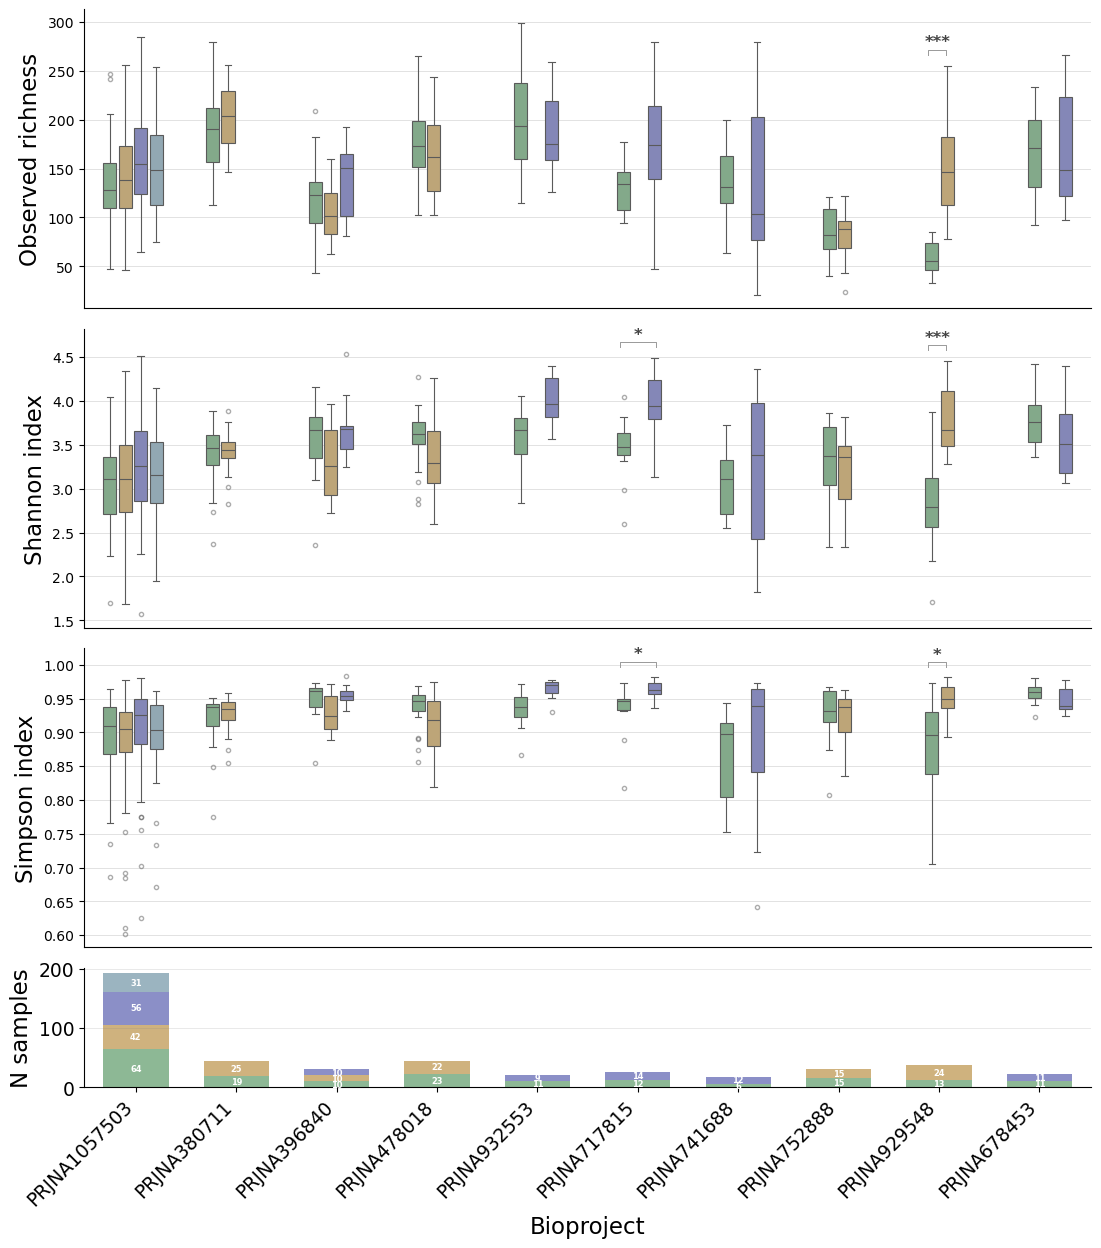

In [5]:
SCALE = 1.5
FS = {
    "ylabel": 11 * SCALE,
    "xlabel": 11 * SCALE,
    "tick": 9 * SCALE,
    "tick_small": 9 * SCALE,
    "stars": 8 * SCALE,
    "bar_label": 4 * SCALE,
}

metrics = [
    ("observed", "Observed richness"),
    ("shannon", "Shannon index"),
    ("simpson", "Simpson index"),
]

bp_order = metadata_alpha["bioproject"].unique().tolist()
bp_to_x = {bp: i for i, bp in enumerate(bp_order)}
n_bp = len(bp_order)

box_width = 0.6
box_gap = 0.15
step = box_width / len(GROUP_ORDER) * (1 + box_gap)
hue_offsets = {
    group: (i - (len(GROUP_ORDER) - 1) / 2) * step
    for i, group in enumerate(GROUP_ORDER)
}

fig = plt.figure(figsize=(n_bp * 1.2 + 1, 14))
gs = fig.add_gridspec(4, 1, height_ratios=[3, 3, 3, 1.2], hspace=0.08)
alpha_axes = [fig.add_subplot(gs[i, 0]) for i in range(3)]
ax_n = fig.add_subplot(gs[3, 0])

for ax, (metric, ylabel) in zip(alpha_axes, metrics):
    boxplot_kwargs = dict(
        data=metadata_alpha,
        x="bioproject",
        y=metric,
        hue="group",
        hue_order=GROUP_ORDER,
        palette=PALETTE,
        order=bp_order,
        ax=ax,
        linewidth=0.8,
        width=box_width,
        flierprops=dict(marker="o", markersize=3, alpha=0.5),
        legend=False,
    )
    try:
        sns.boxplot(**boxplot_kwargs, gap=box_gap)
    except TypeError:
        sns.boxplot(**boxplot_kwargs)

    metric_min = metadata_alpha[metric].min()
    metric_max = metadata_alpha[metric].max()
    metric_range = metric_max - metric_min if metric_max != metric_min else 1

    for bp in bp_order:
        bp_x = bp_to_x[bp]
        sub = metadata_alpha[metadata_alpha["bioproject"] == bp]
        present_groups = [
            group for group in GROUP_ORDER
            if len(sub.loc[sub["group"] == group, metric].dropna()) >= 3
        ]
        if len(present_groups) < 2:
            continue

        y_base = sub[metric].max() + metric_range * 0.04
        for group1, group2 in combinations(present_groups, 2):
            row = alpha_tests[
                (alpha_tests["metric"] == metric)
                & (alpha_tests["bioproject"] == bp)
                & (alpha_tests["group1"] == group1)
                & (alpha_tests["group2"] == group2)
            ]
            if row.empty:
                continue

            stars = pval_to_stars(row["q_value"].iloc[0])
            if stars is None:
                continue

            x1 = bp_x + hue_offsets[group1]
            x2 = bp_x + hue_offsets[group2]
            h = metric_range * 0.02
            ax.plot([x1, x1, x2, x2], [y_base, y_base + h, y_base + h, y_base],
                    color="#999", linewidth=0.7)
            ax.text((x1 + x2) / 2, y_base + h, stars,
                    ha="center", va="bottom", fontsize=FS["stars"],
                    color="#444", fontweight="bold")
            y_base += metric_range * 0.10

    ax.set_ylabel(ylabel, fontsize=FS["ylabel"])
    ax.set_xlabel("")
    ax.set_title("")
    ax.tick_params(axis="x", labelbottom=False, bottom=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", linewidth=0.4, alpha=0.4, color="gray")
    ax.margins(x=0.02)

for bp in bp_order:
    bp_x = bp_to_x[bp]
    sub = metadata_alpha[metadata_alpha["bioproject"] == bp]
    bottom = 0
    total = sum(len(sub.loc[sub["group"] == group].dropna(subset=["observed"])) for group in GROUP_ORDER)

    for group in GROUP_ORDER:
        n = len(sub.loc[sub["group"] == group].dropna(subset=["observed"]))
        if n == 0:
            continue

        ax_n.bar(bp_x, n, bottom=bottom, width=0.65,
                 color=PALETTE[group], alpha=0.88, linewidth=0)
        if n / max(total, 1) >= 0.08:
            ax_n.text(bp_x, bottom + n / 2, str(n),
                      ha="center", va="center", fontsize=FS["bar_label"],
                      color="white", fontweight="bold")
        bottom += n

ax_n.set_ylabel("N samples", fontsize=FS["ylabel"])
ax_n.set_xlabel("Bioproject", fontsize=FS["xlabel"])
ax_n.tick_params(labelsize=FS["tick_small"])
ax_n.spines[["top", "right"]].set_visible(False)
ax_n.grid(axis="y", linewidth=0.4, alpha=0.3, color="gray")
ax_n.set_xticks(range(n_bp))
ax_n.set_xticklabels(bp_order, rotation=45, ha="right", fontsize=FS["tick_small"])
ax_n.margins(x=0.02)

fig.savefig(FIG_DIR / "Fig_2_taxonomic_alpha_diversity.svg", bbox_inches="tight", transparent=True)
plt.show()

## Taxonomic beta-diversity distances

In [6]:
bc_dm = beta_diversity(
    metric="braycurtis",
    counts=tax_data.values,
    ids=tax_data.index.tolist(),
)
bc_df = pd.DataFrame(bc_dm.data, index=bc_dm.ids, columns=bc_dm.ids)
bc_df.to_csv(DIST_DIR / "bray_curtis_taxa.csv")

clr_data = np.log(tax_data + CLR_PSEUDO)
clr_data = clr_data.subtract(clr_data.mean(axis=1), axis=0)

aitchison_dist = squareform(pdist(clr_data.values, metric="euclidean"))
at_dm = DistanceMatrix(aitchison_dist, ids=clr_data.index.tolist())
at_df = pd.DataFrame(at_dm.data, index=at_dm.ids, columns=at_dm.ids)
at_df.to_csv(DIST_DIR / "aitchison_taxa.csv")

print(f"Saved distance matrices to: {DIST_DIR}")
print(f"Bray-Curtis: {bc_df.shape}")
print(f"Aitchison: {at_df.shape}")

Saved distance matrices to: /srv/common/microbime_data/distances
Bray-Curtis: (514, 514)
Aitchison: (514, 514)


## PCoA and PERMANOVA

In [7]:
bc_df = pd.read_csv(DIST_DIR / "bray_curtis_taxa.csv", index_col=0)
at_df = pd.read_csv(DIST_DIR / "aitchison_taxa.csv", index_col=0)

bc_dm = DistanceMatrix(bc_df.values, ids=bc_df.index.tolist())
at_dm = DistanceMatrix(at_df.values, ids=at_df.index.tolist())

bc_pcoa = pcoa(bc_dm)
at_pcoa = pcoa(at_dm)

bc_coords = bc_pcoa.samples[["PC1", "PC2"]].rename(columns={"PC1": "bc_PC1", "PC2": "bc_PC2"})
at_coords = at_pcoa.samples[["PC1", "PC2"]].rename(columns={"PC1": "at_PC1", "PC2": "at_PC2"})
metadata = metadata.drop(columns=["bc_PC1", "bc_PC2", "at_PC1", "at_PC2"], errors="ignore")
metadata = metadata.join(bc_coords).join(at_coords)

bc_var = bc_pcoa.proportion_explained
at_var = at_pcoa.proportion_explained

print(f"Bray-Curtis PC1={bc_var.iloc[0]:.1%}, PC2={bc_var.iloc[1]:.1%}")
print(f"Aitchison PC1={at_var.iloc[0]:.1%}, PC2={at_var.iloc[1]:.1%}")

/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:164: RuntimeWarning: EIGH: since no value for dimensions is specified, PCoA for all dimensions will be computed, which may result in long computation time if the original distance matrix is large.
  warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:282: RuntimeWarning: The result contains negative eigenvalues that are large in magnitude, which may suggest result inaccuracy. See Notes for details. The negative-most eigenvalue is -0.6552647517297058 whereas the largest positive one is 22.531804676113293.
  warn(


Bray-Curtis PC1=13.7%, PC2=10.6%
Aitchison PC1=9.2%, PC2=8.5%


In [8]:
common_ids = [run for run in bc_dm.ids if run in metadata.index]
meta_perm = metadata.loc[common_ids]

bc_dm_f = DistanceMatrix(np.ascontiguousarray(bc_dm.filter(common_ids).data), ids=common_ids)
at_dm_f = DistanceMatrix(np.ascontiguousarray(at_dm.filter(common_ids).data), ids=common_ids)

perm_bc_bp = permanova_r2(bc_dm_f, meta_perm["bioproject"])
perm_bc_group = permanova_r2(bc_dm_f, meta_perm["group"])
perm_at_bp = permanova_r2(at_dm_f, meta_perm["bioproject"])
perm_at_group = permanova_r2(at_dm_f, meta_perm["group"])

print("Bray-Curtis:")
print(f"  study R2={perm_bc_bp['R2']:.4f}, p={perm_bc_bp['p_value']:.3f}")
print(f"  group R2={perm_bc_group['R2']:.4f}, p={perm_bc_group['p_value']:.3f}")
print(f"  study/group R2 ratio = {perm_bc_bp['R2'] / max(perm_bc_group['R2'], 1e-6):.1f}x")

print("\nAitchison:")
print(f"  study R2={perm_at_bp['R2']:.4f}, p={perm_at_bp['p_value']:.3f}")
print(f"  group R2={perm_at_group['R2']:.4f}, p={perm_at_group['p_value']:.3f}")
print(f"  study/group R2 ratio = {perm_at_bp['R2'] / max(perm_at_group['R2'], 1e-6):.1f}x")

Bray-Curtis:
  study R2=0.2831, p=0.001
  group R2=0.0364, p=0.001
  study/group R2 ratio = 7.8x

Aitchison:
  study R2=0.1936, p=0.001
  group R2=0.0348, p=0.001
  study/group R2 ratio = 5.6x


## Taxonomic ordination plot

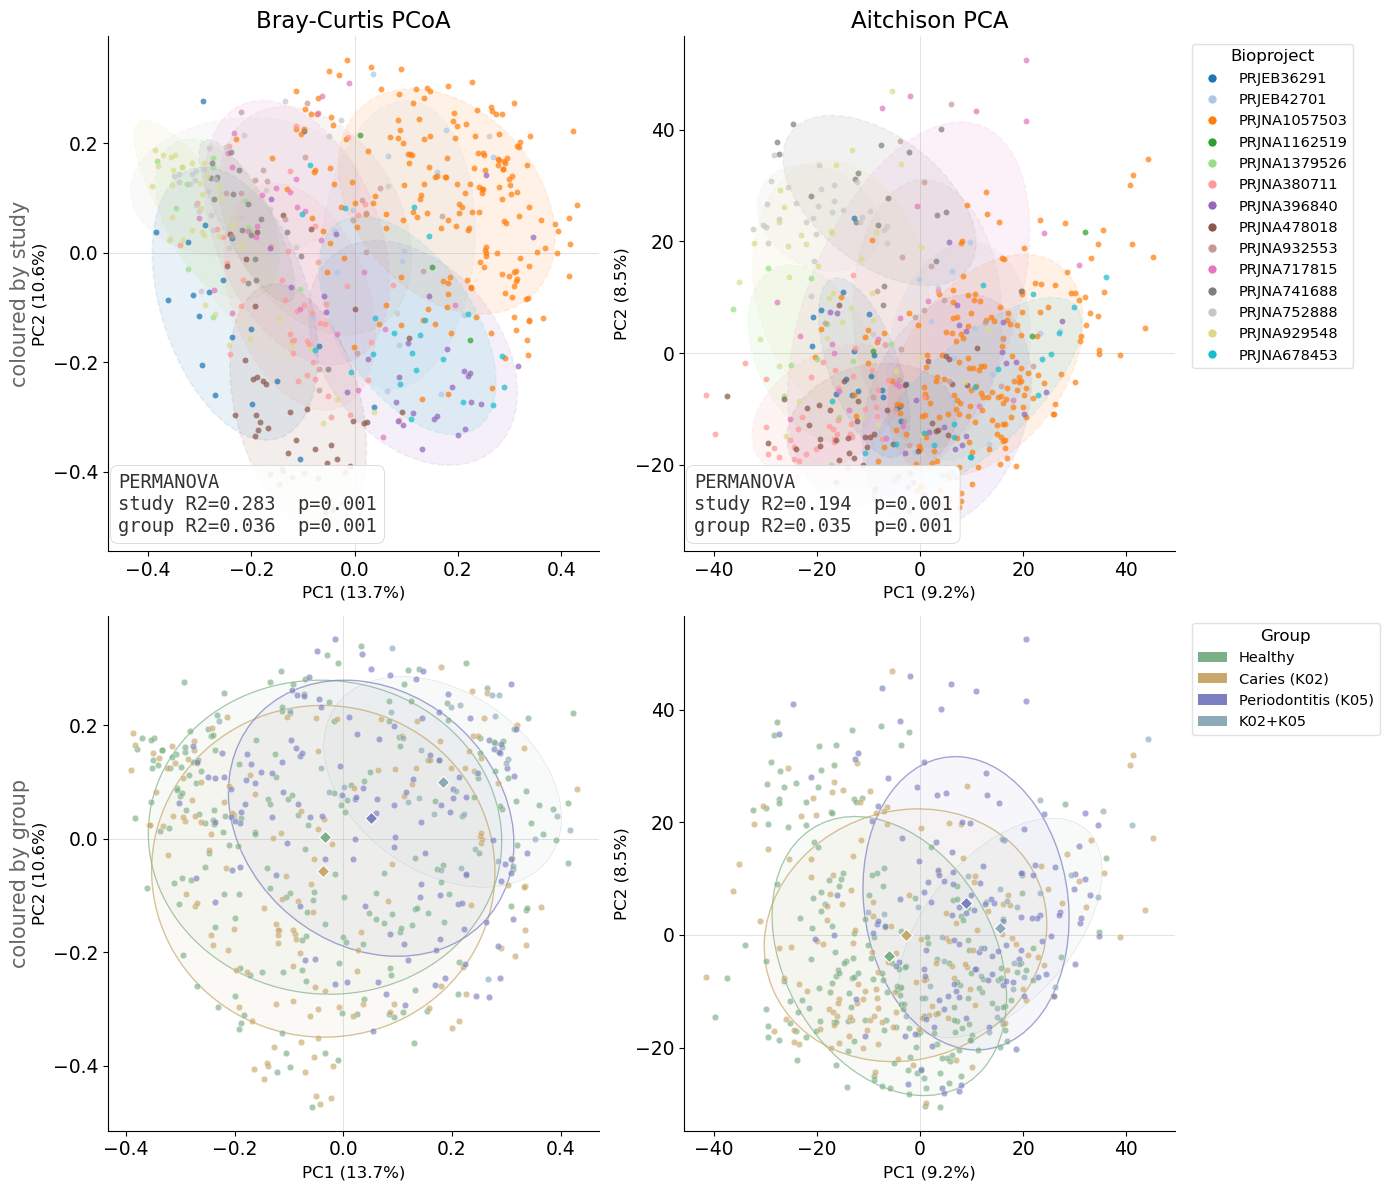

In [9]:
def permanova_label(study_result: dict, group_result: dict) -> str:
    return (
        "PERMANOVA\n"
        f"study R2={study_result['R2']:.3f}  p={study_result['p_value']:.3f}\n"
        f"group R2={group_result['R2']:.3f}  p={group_result['p_value']:.3f}"
    )


SCALE = 1.5
FS = {
    "title": 11 * SCALE,
    "axis_label": 8 * SCALE,
    "tick": 9 * SCALE,
    "perm_box": 9 * SCALE,
    "row_label": 10 * SCALE,
    "legend": 7 * SCALE,
    "legend_title": 8 * SCALE,
}

bp_order = metadata["bioproject"].unique().tolist()
bp_cmap = plt.cm.tab20
bp_colors = {bp: bp_cmap(i / max(len(bp_order), 1)) for i, bp in enumerate(bp_order)}

bc_var1, bc_var2 = bc_var.iloc[0], bc_var.iloc[1]
at_var1, at_var2 = at_var.iloc[0], at_var.iloc[1]

label_bc = permanova_label(perm_bc_bp, perm_bc_group)
label_at = permanova_label(perm_at_bp, perm_at_group)

ellipse_style = {
    "Healthy": dict(linestyle="-", linewidth=0.9, zorder=2),
    "Caries (K02)": dict(linestyle="-", linewidth=1.0, zorder=3),
    "Periodontitis (K05)": dict(linestyle="-", linewidth=1.0, zorder=4),
    "K02+K05": dict(linestyle="-", linewidth=0.2, zorder=2),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.patch.set_facecolor("none")

configs = [
    (axes[0, 0], "bc_PC1", "bc_PC2", "study", label_bc, "Bray-Curtis PCoA"),
    (axes[0, 1], "at_PC1", "at_PC2", "study", label_at, "Aitchison PCA"),
    (axes[1, 0], "bc_PC1", "bc_PC2", "group", None, ""),
    (axes[1, 1], "at_PC1", "at_PC2", "group", None, ""),
]

for ax, x_col, y_col, color_by, perm_text, title in configs:
    ax.set_facecolor("none")

    if color_by == "study":
        for bp in bp_order:
            sub = metadata[metadata["bioproject"] == bp]
            color = bp_colors[bp]
            ax.scatter(sub[x_col], sub[y_col], c=[color], s=18, alpha=0.72, linewidths=0, zorder=3)
            confidence_ellipse(
                sub[x_col].values,
                sub[y_col].values,
                ax,
                edgecolor=color,
                facecolor=color,
                alpha=0.1,
                linewidth=1.2,
                linestyle="--",
            )

        ax.text(
            0.02,
            0.03,
            perm_text,
            transform=ax.transAxes,
            fontsize=FS["perm_box"],
            va="bottom",
            ha="left",
            color="#333",
            fontfamily="monospace",
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#ccc", lw=0.5, alpha=0.9),
        )

    else:
        for group in GROUP_ORDER:
            sub = metadata[metadata["group"] == group]
            if sub.empty:
                continue
            ax.scatter(
                sub[x_col],
                sub[y_col],
                c=PALETTE[group],
                s=22,
                alpha=0.65,
                label=group,
                linewidths=0.3,
                edgecolors="white",
                zorder=5,
            )
            ax.scatter(
                sub[x_col].mean(),
                sub[y_col].mean(),
                color=PALETTE[group],
                s=40,
                marker="D",
                edgecolors="white",
                linewidths=0.78,
                zorder=7,
            )
            r, g, b = mcolors.to_rgb(PALETTE[group])
            confidence_ellipse(
                sub[x_col].values,
                sub[y_col].values,
                ax,
                edgecolor=(r, g, b, 0.70),
                facecolor=(r, g, b, 0.06),
                clip_on=False,
                **ellipse_style[group],
            )

    ax.axhline(0, color="gray", linewidth=0.4, alpha=0.4)
    ax.axvline(0, color="gray", linewidth=0.4, alpha=0.4)
    ax.set_title(title, fontsize=FS["title"], pad=6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=FS["tick"])

axes[0, 0].set_ylabel(f"PC2 ({bc_var2:.1%})", fontsize=FS["axis_label"])
axes[1, 0].set_ylabel(f"PC2 ({bc_var2:.1%})", fontsize=FS["axis_label"])
axes[0, 1].set_ylabel(f"PC2 ({at_var2:.1%})", fontsize=FS["axis_label"])
axes[1, 1].set_ylabel(f"PC2 ({at_var2:.1%})", fontsize=FS["axis_label"])

axes[0, 0].set_xlabel(f"PC1 ({bc_var1:.1%})", fontsize=FS["axis_label"])
axes[1, 0].set_xlabel(f"PC1 ({bc_var1:.1%})", fontsize=FS["axis_label"])
axes[0, 1].set_xlabel(f"PC1 ({at_var1:.1%})", fontsize=FS["axis_label"])
axes[1, 1].set_xlabel(f"PC1 ({at_var1:.1%})", fontsize=FS["axis_label"])

for ax, label in [(axes[0, 0], "coloured by study"), (axes[1, 0], "coloured by group")]:
    ax.annotate(
        label,
        xy=(-0.18, 0.5),
        xycoords="axes fraction",
        fontsize=FS["row_label"],
        rotation=90,
        va="center",
        ha="center",
        color="#666",
    )

bp_handles = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=bp_colors[bp], markersize=7, label=bp)
    for bp in bp_order
]
axes[0, 1].legend(
    handles=bp_handles,
    title="Bioproject",
    fontsize=FS["legend"],
    title_fontsize=FS["legend_title"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    framealpha=0.85,
    edgecolor="#ddd",
)

group_handles = [plt.matplotlib.patches.Patch(facecolor=PALETTE[group], label=group, linewidth=0) for group in GROUP_ORDER]
axes[1, 1].legend(
    handles=group_handles,
    title="Group",
    fontsize=FS["legend"],
    title_fontsize=FS["legend_title"],
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    framealpha=0.85,
    edgecolor="#ddd",
)

plt.tight_layout()
fig.savefig(FIG_DIR / "Fig_2_taxonomic_beta_ordination.svg", bbox_inches="tight", transparent=True)
plt.show()